In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA

In [2]:
data_clean = pd.read_csv("../data/processed/vehicle_co2_clean.csv")

print("Dataset shape:", data_clean.shape)
print("\nColumns:")
print(data_clean.columns.tolist())

Dataset shape: (5985, 14)

Columns:
['make', 'model', 'vehicle_class', 'engine_size', 'cylinders', 'transmission', 'fuel_type', 'co2', 'transmission_gears', 'transmission_type', 'engine_per_cylinder', 'engine_x_cylinders', 'engine_size_sq', 'cylinders_sq']


In [3]:
engineering_features = [
    "engine_size",
    "cylinders",
    "transmission_gears"
]

print("Missing values in clustering features:")
print(data_clean[engineering_features].isnull().sum())

print("\nSummary statistics:")
print(data_clean[engineering_features].describe().round(3))

Missing values in clustering features:
engine_size           0
cylinders             0
transmission_gears    0
dtype: int64

Summary statistics:
       engine_size  cylinders  transmission_gears
count     5985.000   5985.000            5985.000
mean         3.160      5.616               6.843
std          1.368      1.853               1.208
min          0.900      3.000               4.000
25%          2.000      4.000               6.000
50%          3.000      6.000               6.000
75%          3.700      6.000               8.000
max          8.400     16.000              10.000


In [4]:
# Prepare and standardise clustering data
cluster_data   = data_clean[engineering_features].copy()
if cluster_data.isnull().any().any():
    raise ValueError(
        "Missing values exist in clustering features. "
        "Please handle them before K-Means clustering."
    )
scaler         = StandardScaler()
cluster_scaled = scaler.fit_transform(cluster_data)

print("Clustering data shape:", cluster_data.shape)

Clustering data shape: (5985, 3)


In [5]:
# K selection — silhouette score AND inertia (elbow method)

k_values          = range(2, 9)
silhouette_scores = []
inertia_values    = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = kmeans.fit_predict(cluster_scaled)

    score   = silhouette_score(cluster_scaled, labels)
    inertia = kmeans.inertia_

    silhouette_scores.append(score)
    inertia_values.append(inertia)

    print(f"K = {k}: Silhouette = {score:.4f}  |  Inertia = {inertia:.2f}")

K = 2: Silhouette = 0.4887  |  Inertia = 9735.98
K = 3: Silhouette = 0.4734  |  Inertia = 6039.99
K = 4: Silhouette = 0.5091  |  Inertia = 4344.93
K = 5: Silhouette = 0.5316  |  Inertia = 3382.02
K = 6: Silhouette = 0.5586  |  Inertia = 2727.96
K = 7: Silhouette = 0.5862  |  Inertia = 2104.11
K = 8: Silhouette = 0.5927  |  Inertia = 1831.42


In [6]:
# Store and save K selection results

k_selection_results = pd.DataFrame({
    "K":                list(k_values),
    "Silhouette_Score": silhouette_scores,
    "Inertia":          inertia_values
})

print(k_selection_results)

k_selection_results.to_csv(
    "../results/tables/k_selection_results.csv", index=False)

   K  Silhouette_Score      Inertia
0  2          0.488688  9735.980572
1  3          0.473356  6039.991372
2  4          0.509128  4344.927551
3  5          0.531617  3382.021838
4  6          0.558596  2727.963579
5  7          0.586223  2104.111926
6  8          0.592714  1831.416097


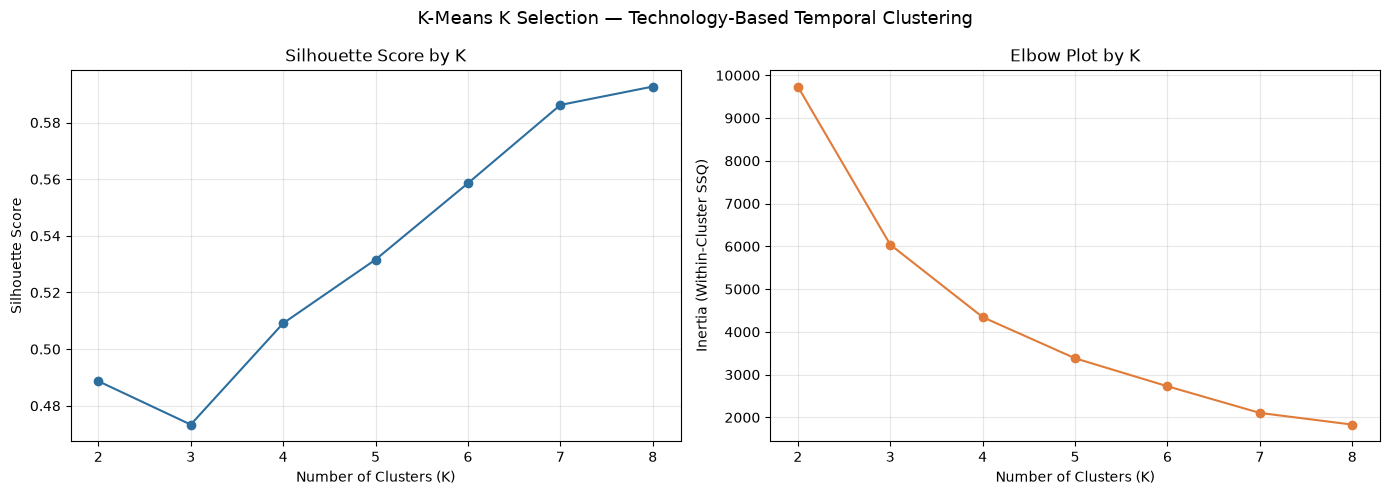

In [7]:
# Plot silhouette scores and elbow side by side

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_values), silhouette_scores, marker="o", color="#2C6E9E")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Silhouette Score")
axes[0].set_title("Silhouette Score by K")
axes[0].set_xticks(list(k_values))
axes[0].grid(True, alpha=0.3)

axes[1].plot(list(k_values), inertia_values, marker="o", color="#E07B39")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Inertia (Within-Cluster SSQ)")
axes[1].set_title("Elbow Plot by K")
axes[1].set_xticks(list(k_values))
axes[1].grid(True, alpha=0.3)

plt.suptitle("K-Means K Selection — Technology-Based Temporal Clustering",
             fontsize=13)
plt.tight_layout()

plt.savefig("../results/figures/k_selection_plots.pdf",
            format="pdf", bbox_inches="tight")
plt.show()
plt.close()

In [8]:
# Select best K — silhouette score primary criterion

best_k_by_silhouette = int(
    k_selection_results.loc[
        k_selection_results["Silhouette_Score"].idxmax(), "K"
    ]
)

print(f"Best K by silhouette score: {best_k_by_silhouette}")

Best K by silhouette score: 8


In [9]:
# Fit final KMeans with best K

best_k = best_k_by_silhouette

kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=20)
cluster_labels = kmeans_final.fit_predict(cluster_scaled)

data_clean["technology_cluster"] = cluster_labels

print(f"Technology clusters created using K = {best_k}")
print("Raw cluster label distribution:")
print(data_clean["technology_cluster"].value_counts().sort_index())

Technology clusters created using K = 8
Raw cluster label distribution:
technology_cluster
0     583
1    2154
2     589
3     930
4     781
5     139
6     474
7     335
Name: count, dtype: int64


In [10]:
# Cluster centres in original units

cluster_centres = pd.DataFrame(
    scaler.inverse_transform(kmeans_final.cluster_centers_),
    columns=engineering_features
)

cluster_centres.index.name = "technology_cluster"

print("\nCluster centres:")
print(cluster_centres.round(3))

cluster_centres.to_csv(
    "../results/tables/technology_cluster_centres.csv"
)


Cluster centres:
                    engine_size  cylinders  transmission_gears
technology_cluster                                            
0                         2.060      3.981               8.333
1                         1.973      3.976               5.991
2                         5.044      8.088               7.626
3                         3.256      5.994               7.624
4                         3.504      6.000               5.919
5                         6.399     11.986               7.583
6                         5.370      8.030               5.819
7                         3.851      6.663               9.472


In [11]:
# Check cluster sizes

cluster_sizes = (
    data_clean["technology_cluster"]
    .value_counts()
    .sort_index()
)

cluster_percentages = (
    cluster_sizes / len(data_clean) * 100
).round(2)

cluster_size_summary = pd.DataFrame({
    "Count": cluster_sizes,
    "Percentage": cluster_percentages
})

print("\nTechnology cluster sizes:")
print(cluster_size_summary)

cluster_size_summary.to_csv(
    "../results/tables/technology_cluster_sizes.csv"
)


Technology cluster sizes:
                    Count  Percentage
technology_cluster                   
0                     583        9.74
1                    2154       35.99
2                     589        9.84
3                     930       15.54
4                     781       13.05
5                     139        2.32
6                     474        7.92
7                     335        5.60


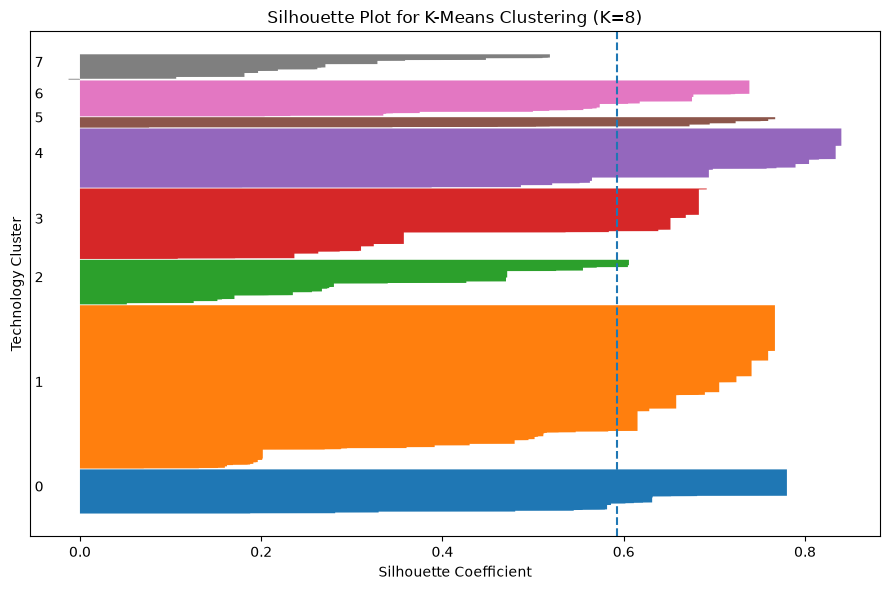

In [12]:
# Silhouette plot for the selected K

sample_silhouette_values = silhouette_samples(
    cluster_scaled,
    cluster_labels
)

average_silhouette = silhouette_score(
    cluster_scaled,
    cluster_labels
)

fig, ax = plt.subplots(
    figsize=(9, 6)
)

y_lower = 10

for cluster in range(best_k):

    cluster_values = sample_silhouette_values[
        cluster_labels == cluster
    ]

    cluster_values.sort()

    cluster_size = len(cluster_values)

    y_upper = y_lower + cluster_size

    ax.fill_betweenx(
        range(y_lower, y_upper),
        0,
        cluster_values
    )

    ax.text(
        -0.05,
        y_lower + 0.5 * cluster_size,
        str(cluster)
    )

    y_lower = y_upper + 10


ax.axvline(
    x=average_silhouette,
    linestyle="--"
)

ax.set_xlabel("Silhouette Coefficient")
ax.set_ylabel("Technology Cluster")

ax.set_title(
    f"Silhouette Plot for K-Means Clustering (K={best_k})"
)

ax.set_yticks([])

plt.tight_layout()

plt.savefig(
    "../results/figures/silhouette_plot.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()
plt.close()


PCA explained variance:
PC1: 67.19%
PC2: 30.48%
Total: 97.67%


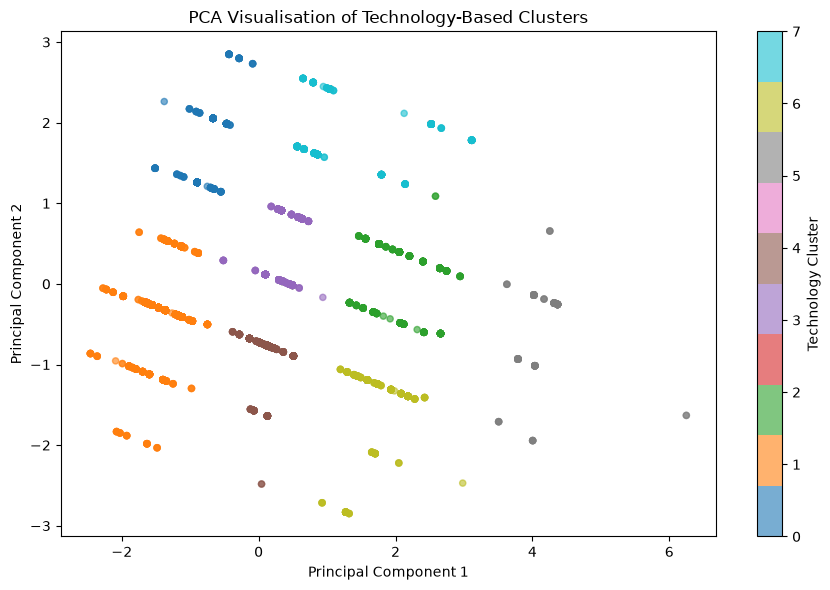

In [13]:
# PCA visualisation of technology clusters

pca = PCA(
    n_components=2,
    random_state=42
)

pca_components = pca.fit_transform(
    cluster_scaled
)

pca_data = pd.DataFrame({
    "PC1": pca_components[:, 0],
    "PC2": pca_components[:, 1],
    "technology_cluster": cluster_labels
})

explained_variance = pca.explained_variance_ratio_

print("\nPCA explained variance:")
print(
    f"PC1: {explained_variance[0] * 100:.2f}%"
)

print(
    f"PC2: {explained_variance[1] * 100:.2f}%"
)

print(
    f"Total: {explained_variance.sum() * 100:.2f}%"
)


# %%
# PCA scatter plot

fig, ax = plt.subplots(
    figsize=(9, 6)
)

scatter = ax.scatter(
    pca_data["PC1"],
    pca_data["PC2"],
    c=pca_data["technology_cluster"],
    cmap="tab10",
    alpha=0.6,
    s=20
)

ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")

ax.set_title(
    "PCA Visualisation of Technology-Based Clusters"
)

fig.colorbar(
    scatter,
    ax=ax,
    label="Technology Cluster"
)

plt.tight_layout()

plt.savefig(
    "../results/figures/pca_technology_clusters.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()
plt.close()


# %%
# Save PCA results

pca_data.to_csv(
    "../results/tables/pca_technology_clusters.csv",
    index=False
)


In [14]:
# Technology cluster profile

cluster_profile = (
    data_clean
    .groupby("technology_cluster")
    .agg(
        count=("co2", "size"),
        mean_engine_size=("engine_size", "mean"),
        mean_cylinders=("cylinders", "mean"),
        mean_transmission_gears=("transmission_gears", "mean"),
        mean_co2=("co2", "mean")
    )
    .round(2)
)

print("\nTechnology cluster profile:")
print(cluster_profile)

cluster_profile.to_csv(
    "../results/tables/technology_cluster_profile.csv"
)


Technology cluster profile:
                    count  mean_engine_size  mean_cylinders  \
technology_cluster                                            
0                     583              2.06            3.98   
1                    2154              1.97            3.98   
2                     589              5.04            8.09   
3                     930              3.26            5.99   
4                     781              3.50            6.00   
5                     139              6.40           11.99   
6                     474              5.37            8.03   
7                     335              3.85            6.66   

                    mean_transmission_gears  mean_co2  
technology_cluster                                     
0                                      8.33    218.02  
1                                      5.99    200.77  
2                                      7.63    316.68  
3                                      7.62    255.52  
4   

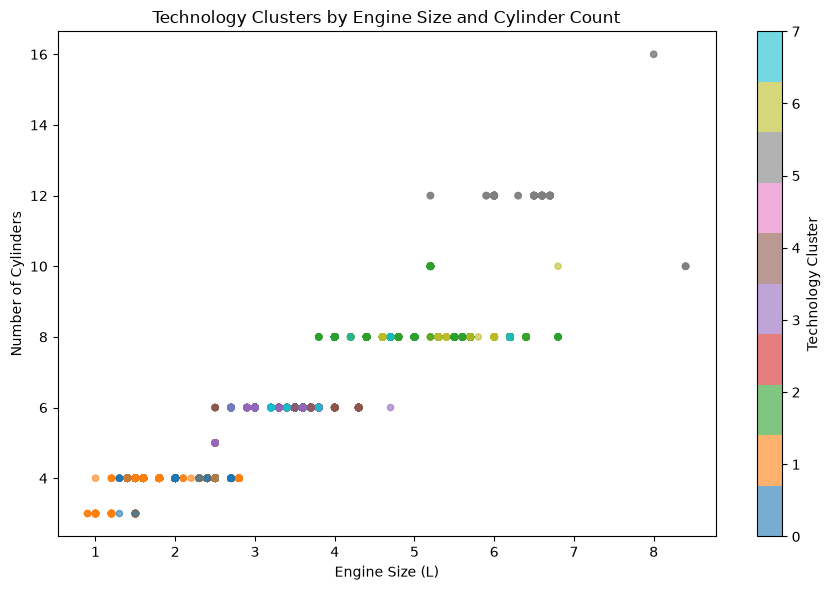

In [15]:
# Visualise clusters — Engine Size vs Cylinders

fig, ax = plt.subplots(figsize=(9, 6))

scatter = ax.scatter(
    data_clean["engine_size"],
    data_clean["cylinders"],
    c=data_clean["technology_cluster"],
    cmap="tab10",
    alpha=0.6,
    s=20
)

ax.set_xlabel("Engine Size (L)")
ax.set_ylabel("Number of Cylinders")
ax.set_title("Technology Clusters by Engine Size and Cylinder Count")
fig.colorbar(scatter, ax=ax, label="Technology Cluster")
plt.tight_layout()

plt.savefig("../results/figures/technology_clusters_engine_cylinders.pdf",
            format="pdf", bbox_inches="tight")
plt.show()
plt.close()


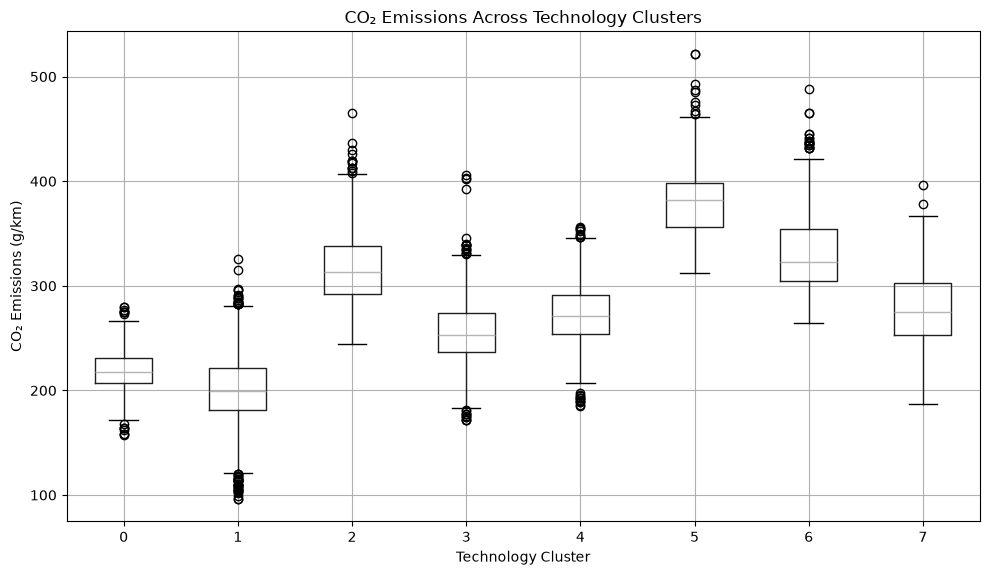

In [16]:
# CO₂ emissions across technology clusters

fig, ax = plt.subplots(figsize=(10, 6))

data_clean.boxplot(column="co2", by="technology_cluster", ax=ax)
ax.set_xlabel("Technology Cluster")
ax.set_ylabel("CO₂ Emissions (g/km)")
ax.set_title("CO₂ Emissions Across Technology Clusters")
plt.suptitle("")
plt.tight_layout()

plt.savefig("../results/figures/co2_by_technology_cluster.pdf",
            format="pdf", bbox_inches="tight")
plt.show()
plt.close()

In [17]:
# Transmission type composition per cluster
transmission_profile = pd.crosstab(
    data_clean["technology_cluster"],
    data_clean["transmission_type"],
    normalize="index"
) * 100

print("Transmission composition by technology cluster (%):")
print(transmission_profile.round(2))

transmission_profile.round(2).to_csv(
    "../results/tables/transmission_cluster_profile.csv")

Transmission composition by technology cluster (%):
transmission_type       A     AM     AS     AV      M
technology_cluster                                   
0                   27.27   1.37  66.04   5.32   0.00
1                   12.81   9.10  31.43  15.97  30.69
2                   27.67  15.28  54.84   0.51   1.70
3                   18.17  20.65  52.15   2.37   6.67
4                   27.14   1.15  46.73   5.63  19.33
5                   22.30  17.27  56.12   0.00   4.32
6                   63.08   0.00  19.83   0.00  17.09
7                   51.04   0.30  47.16   1.49   0.00


In [18]:
# Save final clustered dataset
data_clean.to_csv(
    "../data/processed/vehicle_co2_technology_clusters.csv",
    index=False
)

print("Final clustered dataset saved.")

Final clustered dataset saved.
